<a href="https://colab.research.google.com/github/ZekraAskarya/Student-Depression-Detection/blob/main/Student_Depression_Detection_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Student Depression Detection.**
Depression among students is a growing concern that affects academic performance, social behavior, and quality of life. The goal of this project is to predict whether a student is at risk of depression based on multiple demographic, lifestyle, and academic-related features.

**Why is the dataset suitable?**


1.   Uncleaned: contains outliers, useless columns and requires encoding...
2.   Realistic Simulation: Reflects actual factors contributing to depression (e.g., GPA, sleep, social media, financial stress, exercise...).
3.   Moderate amount of rows and columns.
4.   Real-world mental health application

**Proposed Output.**

A predictive web application (via Streamlit) that allows institutions or mental health researchers to input student attributes and assess depression risk.




# Dataset upload and basic inspections

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Student Depression Dataset.csv to Student Depression Dataset.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('Student Depression Dataset.csv')

print("Shape:", df.shape)
df.head()

Shape: (27901, 18)


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  object 
 11  Di

In [ ]:
df.describe()

,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27898.000000,27901.000000
mean,70442.149421,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,3.139867,0.585499
std,40641.175216,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,1.437347,0.492645
min,2.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,35039.000000,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000,0.000000
50%,70684.000000,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000,1.000000
75%,105818.000000,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000,1.000000
max,140699.000000,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000,1.000000


# Data Preprocessing

In [ ]:
# Drop some columns that seem useless

df.drop(['id', 'Profession', 'City'], axis=1, inplace=True)
# Column "id" is just an identifier, column "Profession" seem useless as almost every instance is a student, and column "City" is uselss.

df.drop(['Work Pressure', 'Job Satisfaction'], axis=1, inplace=True)
# Columns "Work Pressure" and "Job Satisfaction" are useless as they are almost filled with zeros

In [ ]:
df.columns

Index(['Gender', 'Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction',
       'Sleep Duration', 'Dietary Habits', 'Degree',
       'Have you ever had suicidal thoughts ?', 'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness', 'Depression'],
      dtype='object')

In [ ]:
df['Sleep Duration'].value_counts()

,count
Sleep Duration,
Less than 5 hours,8310
7-8 hours,7346
5-6 hours,6183
More than 8 hours,6044
Others,18


In [ ]:
# Only 18 rows with "Others", so they will be dropped before encoding.
df = df[df['Sleep Duration'] != "Others"]

In [ ]:
# Ordinal Encoding
sleep_map = {
    "Less than 5 hours": 0,
    "5-6 hours": 1,
    "7-8 hours": 2,
    "More than 8 hours": 3
}
df['Sleep Duration'] = df['Sleep Duration'].map(sleep_map)

In [ ]:
df.head(5)

,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Male,33.0,5.0,8.97,2.0,1,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,Female,24.0,2.0,5.90,5.0,1,Moderate,BSc,No,3.0,2.0,Yes,0
2,Male,31.0,3.0,7.03,5.0,0,Healthy,BA,No,9.0,1.0,Yes,0
3,Female,28.0,3.0,5.59,2.0,2,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,Female,25.0,4.0,8.13,3.0,1,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [ ]:
df['Sleep Duration'].unique()


array([1, 0, 2, 3])

In [ ]:
# Binary encoding
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Have you ever had suicidal thoughts ?'] = df['Have you ever had suicidal thoughts ?'].map({'No': 0, 'Yes': 1})
df['Family History of Mental Illness'] = df['Family History of Mental Illness'].map({'No': 0, 'Yes': 1})

In [ ]:
df[['Gender', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']].head()

,Gender,Have you ever had suicidal thoughts ?,Family History of Mental Illness
0,0,1,0
1,1,0,1
2,0,0,1
3,1,1,1
4,1,1,0


In [ ]:
df['Degree'].value_counts()

,count
Degree,
Class 12,6080
B.Ed,1866
B.Com,1505
B.Arch,1476
BCA,1433
MSc,1189
B.Tech,1152
MCA,1043
M.Tech,1020


In [ ]:
# Only 35 rows with "Others", they will be dropped before encoding
df = df[df['Degree'] != 'Others']

In [ ]:
# One-hot encoding will be performed
degree_encoded = pd.get_dummies(df['Degree'], prefix='Degree', drop_first=True)
df.drop('Degree', axis=1, inplace=True)
df = pd.concat([df, degree_encoded], axis=1)

In [ ]:
df.head()

,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,...,Degree_M.Tech,Degree_MA,Degree_MBA,Degree_MBBS,Degree_MCA,Degree_MD,Degree_ME,Degree_MHM,Degree_MSc,Degree_PhD
0,0,33.0,5.0,8.97,2.0,1,Healthy,1,3.0,1.0,...,False,False,False,False,False,False,False,False,False,False
1,1,24.0,2.0,5.90,5.0,1,Moderate,0,3.0,2.0,...,False,False,False,False,False,False,False,False,False,False
2,0,31.0,3.0,7.03,5.0,0,Healthy,0,9.0,1.0,...,False,False,False,False,False,False,False,False,False,False
3,1,28.0,3.0,5.59,2.0,2,Moderate,1,4.0,5.0,...,False,False,False,False,False,False,False,False,False,False
4,1,25.0,4.0,8.13,3.0,1,Moderate,1,1.0,1.0,...,True,False,False,False,False,False,False,False,False,False


In [ ]:
# converting boolean variables to 0s and 1s
df = df.apply(lambda col: col.astype(int) if col.dtype == 'bool' else col)

In [ ]:
df.head()

,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,...,Degree_M.Tech,Degree_MA,Degree_MBA,Degree_MBBS,Degree_MCA,Degree_MD,Degree_ME,Degree_MHM,Degree_MSc,Degree_PhD
0,0,33.0,5.0,8.97,2.0,1,Healthy,1,3.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,1,24.0,2.0,5.90,5.0,1,Moderate,0,3.0,2.0,...,0,0,0,0,0,0,0,0,0,0
2,0,31.0,3.0,7.03,5.0,0,Healthy,0,9.0,1.0,...,0,0,0,0,0,0,0,0,0,0
3,1,28.0,3.0,5.59,2.0,2,Moderate,1,4.0,5.0,...,0,0,0,0,0,0,0,0,0,0
4,1,25.0,4.0,8.13,3.0,1,Moderate,1,1.0,1.0,...,1,0,0,0,0,0,0,0,0,0


In [ ]:
df['Dietary Habits'].value_counts()

,count
Dietary Habits,
Unhealthy,10292
Moderate,9905
Healthy,7639
Others,12


In [ ]:
# Only 12 rows with "Others", they will be dropped before encoding
df = df[df['Dietary Habits'] != 'Others']

In [ ]:
# Ordinal Encoding
diet_map = {
    'Unhealthy': 0,
    'Moderate': 1,
    'Healthy': 2
}
df['Dietary Habits'] = df['Dietary Habits'].map(diet_map)

In [ ]:
df.head()

,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,...,Degree_M.Tech,Degree_MA,Degree_MBA,Degree_MBBS,Degree_MCA,Degree_MD,Degree_ME,Degree_MHM,Degree_MSc,Degree_PhD
0,0,33.0,5.0,8.97,2.0,1,2,1,3.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,1,24.0,2.0,5.90,5.0,1,1,0,3.0,2.0,...,0,0,0,0,0,0,0,0,0,0
2,0,31.0,3.0,7.03,5.0,0,2,0,9.0,1.0,...,0,0,0,0,0,0,0,0,0,0
3,1,28.0,3.0,5.59,2.0,2,1,1,4.0,5.0,...,0,0,0,0,0,0,0,0,0,0
4,1,25.0,4.0,8.13,3.0,1,1,1,1.0,1.0,...,1,0,0,0,0,0,0,0,0,0


In [ ]:
df.isnull().sum()

,0
Gender,0
Age,0
Academic Pressure,0
CGPA,0
Study Satisfaction,0
Sleep Duration,0
Dietary Habits,0
Have you ever had suicidal thoughts ?,0
Work/Study Hours,0
Financial Stress,3


In [ ]:
# 3 missing values in "Financial Stress" column, rows will be dropped
df = df[df['Financial Stress'].notna()]

In [ ]:
# Feature Engineering
# A column represnting total stress from academics and money
df['Stress_Index'] = df['Academic Pressure'] + df['Financial Stress']
df['Stress_Index'].describe()

,Stress_Index
count,27833.000000
mean,6.281464
std,2.139644
min,1.000000
25%,5.000000
50%,6.000000
75%,8.000000
max,10.000000


In [ ]:
df.head(10)

,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,...,Degree_MA,Degree_MBA,Degree_MBBS,Degree_MCA,Degree_MD,Degree_ME,Degree_MHM,Degree_MSc,Degree_PhD,Stress_Index
0,0,33.0,5.0,8.97,2.0,1,2,1,3.0,1.0,...,0,0,0,0,0,0,0,0,0,6.0
1,1,24.0,2.0,5.90,5.0,1,1,0,3.0,2.0,...,0,0,0,0,0,0,0,0,0,4.0
2,0,31.0,3.0,7.03,5.0,0,2,0,9.0,1.0,...,0,0,0,0,0,0,0,0,0,4.0
3,1,28.0,3.0,5.59,2.0,2,1,1,4.0,5.0,...,0,0,0,0,0,0,0,0,0,8.0
4,1,25.0,4.0,8.13,3.0,1,1,1,1.0,1.0,...,0,0,0,0,0,0,0,0,0,5.0
5,0,29.0,2.0,5.70,3.0,0,2,0,4.0,1.0,...,0,0,0,0,0,0,0,0,1,3.0
6,0,30.0,3.0,9.54,4.0,2,2,0,1.0,2.0,...,0,0,0,0,0,0,0,0,0,5.0
7,1,30.0,2.0,8.04,4.0,0,0,0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,3.0
8,0,28.0,3.0,9.79,1.0,2,1,1,12.0,3.0,...,0,0,0,0,0,0,0,0,0,6.0
9,0,31.0,2.0,8.38,3.0,0,1,1,2.0,5.0,...,0,0,0,0,0,0,0,0,0,7.0


In [ ]:
# Some visualizations for detecting outliers in numerical features
import plotly.express as px
import plotly.graph_objects as go

cols = ['Age', 'CGPA', 'Work/Study Hours']

fig = go.Figure()

for col in cols:
    fig.add_trace(go.Box(
        y=df[col],
        name=col,
        boxpoints='outliers',  # show only outliers
        marker=dict(color='crimson'),
        line=dict(color='royalblue'),
    ))

fig.update_layout(
    title='Boxplots of Numerical Features',
    yaxis_title='Value',
    template='plotly_white',
    showlegend=False,
    height=500,
    width=900
)

fig.show()


In [ ]:
# Outliers detected in column "Age"
from datasist.structdata import detect_outliers

outliers = detect_outliers(df, 0, ['Age'])
mean_value = df['Age'].mean()
df.loc[outliers, 'Age'] = mean_value

cgpa_outlier = detect_outliers(df, 0, ['CGPA'])
mean_cgpa = df['CGPA'].mean()
df.loc[cgpa_outlier, 'CGPA'] = mean_cgpa

<Axes: xlabel='Age'>

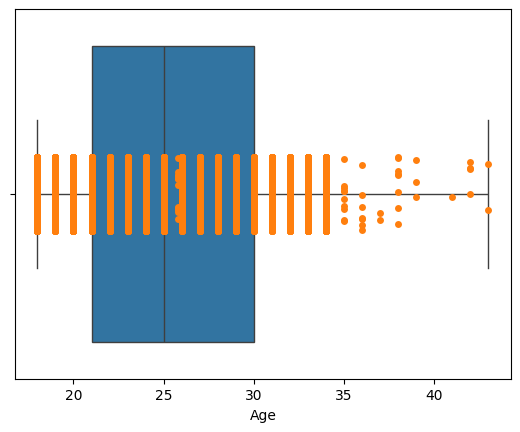

In [ ]:
import seaborn as sns
sns.boxplot(x="Age",data=df)
sns.stripplot(x="Age",data=df)

# Exploratory Data Analysis (EDA)

In [ ]:
# Show how balanced or imbalanced is the dataset
px.histogram(df, x='Depression', color='Depression', barmode='group',
             title='Depression Label Distribution')

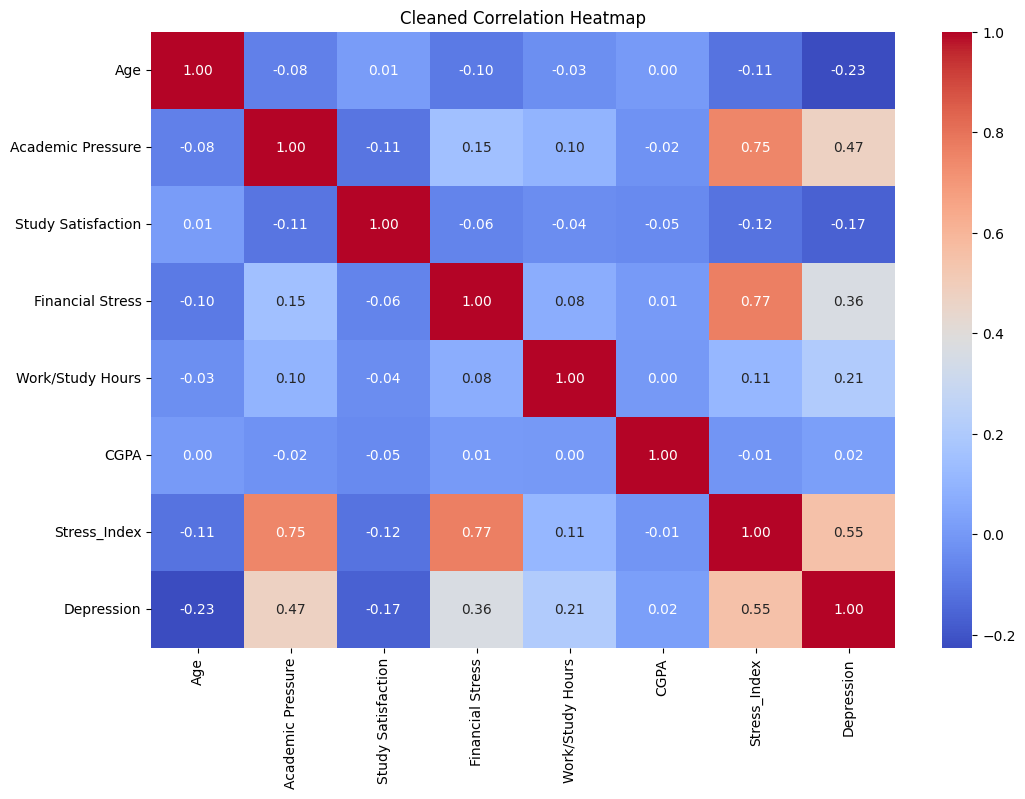

In [ ]:
# Correlation Heatmap
import matplotlib.pyplot as plt

corr_cols = [
    'Age',
    'Academic Pressure',
    'Study Satisfaction',
    'Financial Stress',
    'Work/Study Hours',
    'CGPA',
    'Stress_Index',
    'Depression'
]

plt.figure(figsize=(12, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Cleaned Correlation Heatmap")
plt.show()

In [ ]:
# Bivariate Plot between depression and sucidal thoughts
df_suicide = df.groupby(['Have you ever had suicidal thoughts ?', 'Depression']).size().unstack()
df_suicide_percent = df_suicide.div(df_suicide.sum(axis=1), axis=0) * 100
df_suicide_percent = df_suicide_percent.reset_index()

df_suicide_percent.columns = ['Suicidal Thoughts', 'No Depression', 'Depression']

df_melted = pd.melt(df_suicide_percent, id_vars='Suicidal Thoughts',
                    value_vars=['No Depression', 'Depression'],
                    var_name='Depression Status', value_name='Percentage')

fig = px.bar(df_melted,
             x='Suicidal Thoughts',
             y='Percentage',
             color='Depression Status',
             barmode='stack',
             title='Depression vs Suicidal Thoughts',
             color_discrete_map={
                 'No Depression': 'lightskyblue',
                 'Depression': 'salmon'
             })

fig.show()


In [ ]:
# Bivariate plot between Academic Pressure and Depression
fig = px.box(df,
             x='Depression',
             y='Academic Pressure',
             color='Depression',
             title='Academic Pressure vs Depression',
             labels={'Depression': 'Depression Status'},
             color_discrete_map={0: 'lightskyblue', 1: 'salmon'})

fig.show()

In [ ]:
# Bivariate plot between depression and sleep duration
sleep_counts = df.groupby(['Sleep Duration', 'Depression']).size().unstack().fillna(0)
sleep_percent = sleep_counts.div(sleep_counts.sum(axis=1), axis=0) * 100
sleep_percent = sleep_percent.reset_index()

sleep_percent.columns = ['Sleep Duration', 'No Depression', 'Depression']
melted = sleep_percent.melt(id_vars='Sleep Duration', var_name='Depression Status', value_name='Percentage')

fig = px.bar(melted,
             x='Sleep Duration',
             y='Percentage',
             color='Depression Status',
             barmode='group',
             title='Depression by Sleep Duration',
             color_discrete_map={'No Depression': 'lightskyblue', 'Depression': 'salmon'})
fig.show()

# Feature Selection

In [ ]:
X = df.drop(columns=['Depression'])
y = df['Depression']
y

,Depression
0,1
1,0
2,0
3,1
4,0
...,...
27896,0
27897,0
27898,0
27899,1


In [ ]:
# Applying feature selection (Filter Method)
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=0)
mi_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})
mi_df = mi_df.sort_values(by='MI Score', ascending=False)
mi_df.head(10)

,Feature,MI Score
37,Stress_Index,0.171526
7,Have you ever had suicidal thoughts ?,0.161796
2,Academic Pressure,0.118912
9,Financial Stress,0.071305
1,Age,0.032629
6,Dietary Habits,0.023597
8,Work/Study Hours,0.021396
4,Study Satisfaction,0.016466
25,Degree_M.Ed,0.010667
21,Degree_Class 12,0.010068


# Model

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.8559367702532783

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.80      0.82      2307
           1       0.86      0.90      0.88      3260

    accuracy                           0.86      5567
   macro avg       0.85      0.85      0.85      5567
weighted avg       0.86      0.86      0.86      5567


Confusion Matrix:
 [[1841  466]
 [ 336 2924]]


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.8500089814981139

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.79      0.81      2307
           1       0.86      0.90      0.87      3260

    accuracy                           0.85      5567
   macro avg       0.85      0.84      0.84      5567
weighted avg       0.85      0.85      0.85      5567


Confusion Matrix:
 [[1814  493]
 [ 342 2918]]


# XGBoost

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    learning_rate=0.1,
    max_depth=5,
    n_estimators=200,
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.8561164002155559

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.80      0.82      2307
           1       0.87      0.89      0.88      3260

    accuracy                           0.86      5567
   macro avg       0.85      0.85      0.85      5567
weighted avg       0.86      0.86      0.86      5567


Confusion Matrix:
 [[1855  452]
 [ 349 2911]]


# SVM

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

Accuracy: 0.8577330698760554

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.79      0.82      2307
           1       0.86      0.90      0.88      3260

    accuracy                           0.86      5567
   macro avg       0.86      0.85      0.85      5567
weighted avg       0.86      0.86      0.86      5567


Confusion Matrix:
 [[1829  478]
 [ 314 2946]]


# Parameter Tuning

**Parameter tuning** is an important step in machine learning that involves finding the best hyperparameter values for each model. It ensures the model generalizes well to new data, improves accuracy, and avoids overfitting. In this project, we applied models like XGBoost, Random Forest, and SVM, we will perform parameter tuning on the best algorithm among these.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.3],
    'max_depth': [3, 5, 7, 10],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 1, 5],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 5, 10]
}

In [ ]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning:

[18:41:06] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.




RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_cons...
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.6, 0.8, 1.0],
                                        'gamma': [0, 1, 5],
                                        'learning_rate': [0.01, 0.05, 0.1, 0.3],
                                        'max_depth': [3, 5, 7, 10],
                                        'n_estimators': [100, 200, 300],
                                        'reg_alpha': [0, 0.1, 1],
                                        'reg_lambda': [1, 5, 10],
                                        'subsample': [0.6, 0.8, 1.0]},
                   random_state=42, scoring='accuracy', verbose=1)

In [ ]:
print("Best Parameters:", random_search.best_params_)

best_xgb = random_search.best_estimator_
y_pred_best = best_xgb.predict(X_test)

Best Parameters: {'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 1, 'colsample_bytree': 0.6}


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_best))

Accuracy: 0.856655290102389

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.80      0.82      2307
           1       0.86      0.90      0.88      3260

    accuracy                           0.86      5567
   macro avg       0.85      0.85      0.85      5567
weighted avg       0.86      0.86      0.86      5567


Confusion Matrix:
 [[1850  457]
 [ 341 2919]]


In [ ]:
# Tuning the Logistic Regression model using GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 300]
}

In [ ]:
LR_Model = LogisticRegression()

grid_search_logreg = GridSearchCV(
    estimator=LR_Model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=3,
    verbose=1,
    n_jobs=-1
)

grid_search_logreg.fit(X_train, y_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



GridSearchCV(cv=3, estimator=LogisticRegression(), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100],
                         'max_iter': [100, 200, 300], 'penalty': ['l2'],
                         'solver': ['lbfgs', 'liblinear']},
             scoring='accuracy', verbose=1)

In [ ]:
print("Best Parameters:", grid_search_logreg.best_params_)

best_logreg = grid_search_logreg.best_estimator_
y_pred_logreg = best_logreg.predict(X_test)

Best Parameters: {'C': 0.1, 'max_iter': 100, 'penalty': 'l2', 'solver': 'lbfgs'}


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("\nClassification Report:\n", classification_report(y_test, y_pred_logreg))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_logreg))

Accuracy: 0.8579126998383331

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.80      0.82      2307
           1       0.86      0.90      0.88      3260

    accuracy                           0.86      5567
   macro avg       0.86      0.85      0.85      5567
weighted avg       0.86      0.86      0.86      5567


Confusion Matrix:
 [[1846  461]
 [ 330 2930]]


**What is Validation and why is it important?**

Validation is a critical step in building reliable machine learning models. It allows us to measure how well our model performs on unseen data during the training process. Without validation, we risk building models that perform well only on the training data but fail in real world scenarios.

In this project, we used cross validation (CV) during model selection and hyperparameter tuning. Cross validation splits the data into multiple folds, training on some and validating on the rest. This helps estimate the model's true performance and reduces variance caused by random data splits.

Validation ensures that we:


*   Detect overfitting and underfitting
*   Select the best performing model
*   Tune hyperparameters more effectively



# Deployment

In [ ]:
import joblib

joblib.dump(best_logreg, 'logistic_model.pkl')

['logistic_model.pkl']

In [ ]:
import pickle

with open('logistic_model.pkl', 'wb') as file:
    pickle.dump(best_logreg, file)

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import pickle

# Load the logistic regression model using pickle
with open('logistic_model.pkl', 'rb') as file:
    model = pickle.load(file)

st.title("🎓 Student Depression Predictor App")
st.write("Provide student information to predict the likelihood of depression.")

# --- User Inputs ---
gender = st.selectbox("Gender", ["Male", "Female"])
age = st.slider("Age", min_value=15, max_value=35, value=20)
academic_pressure = st.slider("Academic Pressure (1=Low, 5=High)", 1, 5, 3)
cgpa = st.number_input("CGPA (0.0 - 4.0)", min_value=0.0, max_value=4.0, value=3.0)
study_satisfaction = st.slider("Study Satisfaction (1=Low, 5=High)", 1, 5, 3)

# Ordinal Sleep Duration
sleep_duration = st.selectbox(
    "Sleep Duration",
    ["Less than 5 hours", "5-6 hours", "7-8 hours", "More than 8 hours"]
)
sleep_map = {
    "Less than 5 hours": 0,
    "5-6 hours": 1,
    "7-8 hours": 2,
    "More than 8 hours": 3
}
sleep_encoded = sleep_map[sleep_duration]

suicidal_thoughts = st.selectbox("Have Suicidal Thoughts?", ["Yes", "No"])
mental_history = st.selectbox("Family History of Mental Illness?", ["Yes", "No"])
study_hours = st.slider("Work/Study Hours", 0, 18, 6)

# --- Input DataFrame ---
input_df = pd.DataFrame({
    'Gender': [1 if gender == "Male" else 0],
    'Age': [age],
    'Academic Pressure': [academic_pressure],
    'CGPA': [cgpa],
    'Study Satisfaction': [study_satisfaction],
    'Sleep Duration': [sleep_encoded],
    'Have you ever had suicidal thoughts ?': [1 if suicidal_thoughts == "Yes" else 0],
    'Family History of Mental Illness': [1 if mental_history == "Yes" else 0],
    'Work/Study Hours': [study_hours]
})

# --- Prediction ---
if st.button("Predict Depression"):
    prediction = model.predict(input_df)[0]
    result = "😔 Likely Depressed" if prediction == 1 else "😊 Not Depressed"
    st.success(f"Prediction: {result}")


Overwriting app.py


In [ ]:
!streamlit run app.py




  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.145.250.2:8501

  Stopping...
  Stopping...
